In [1]:
# ruff: noqa: F401
import json

from dotenv import load_dotenv
from IPython.display import Image, display
from langchain.agents import create_agent
from langchain.agents.middleware import wrap_tool_call
from langchain_core.tools import tool
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain_mcp_adapters.tools import load_mcp_tools
from langgraph.checkpoint.memory import MemorySaver as InMemoryServer
from pydantic import BaseModel
from rich.console import Console
from rich.markdown import Markdown
from rich.theme import Theme

# Rich defaults h2/h3/h4 and block_quote to magenta, which is hard to read on dark backgrounds
markdown_theme = Theme(
    {
        "markdown.h1": "bold bright_white underline",
        "markdown.h2": "bold bright_white underline",
        "markdown.h3": "bold bright_white",
        "markdown.h4": "italic bright_white",
        "markdown.block_quote": "bright_white",
        "markdown.code": "bold cyan",
        "markdown.code_block": "cyan on grey15",
        "markdown.link": "bold bright_blue",
        "markdown.item.bullet": "bold bright_white",
        "json.null": "italic bright_white",
        "json.key": "bold bright_cyan",
    }
)

console = Console(theme=markdown_theme, style="bright_white on grey11")

load_dotenv(override=True)

True

### Creating and Invoking Agent


In [2]:
# Using invoke method
agent = create_agent(
    model="openai:gpt-5.4-nano",
    system_prompt="You are an expert assistant who responds to questions concisely",
)

response = agent.invoke(
    input={
        "messages": [
            {
                "role": "user",
                "content": "Please explain me the concept of model context protocol in two sentences",
            }
        ]
    }
)

console.print(response["messages"][-1].content)

The Model Context Protocol (MCP) is a standard way for AI models to securely connect to external tools, data 
sources, and services so they can use up-to-date context. It defines a common interface that helps models request 
and receive structured information from these systems in a consistent way.

In [3]:
# Using ainvoke method

response = await agent.ainvoke(
    input={
        "messages": [
            {
                "role": "user",
                "content": ("In waht way is ainvoke better than invoke while calling LangChain agents?"),
            }
        ]
    }
)

console.print(Markdown(response["messages"][-1].content))


In LangChain, ainvoke is the async version of invoke.                                                              

Key differences when using agents                                                                                  

 • invoke: runs synchronously (blocks the current thread until the agent finishes).                                
 • ainvoke: runs asynchronously (doesn’t block; you can await it, and the event loop can keep working).            

Why ainvoke can be “better” for agents                                                                             

 • Concurrency / responsiveness: If you’re running multiple agent calls, or integrating into an async web server   
   (FastAPI, etc.), ainvoke lets you handle other requests while the agent is working.                             
 • Better scalability: Async I/O is especially helpful when the agent is waiting on network calls (LLM calls,      
   tools, APIs).                                                                                                   
 • Avoid thread blocking: With invoke, you may block a worker thread; with ainvoke, you generally avoid that.      

When invoke is fine                                                                                                

 • Simple scripts / one-off calls where you don’t have an async app or concurrency needs.                          

If you tell me your environment (e.g., FastAPI, asyncio batch, notebooks), I can recommend which one to use.       

### Using tools


In [4]:
@tool
def get_weather(city: str) -> str:
    """Get the weather updates"""
    mock_update = {"Kolkata": "clear with 36 degrees", "Delhi": "Cloudy with 40 degrees"}
    return mock_update.get(city, "clear sky with 25 degrees")


@tool
def get_population(city: str) -> str:
    """Get the population of a city"""
    mock_population = {"Kolkata": "Population 1.5 million", "Delhi": "Population 3.6 million"}
    return mock_population.get(city, "Population 300 thousands")


tools = [get_weather, get_population]

agent = create_agent(
    model="openai:gpt-5.4-nano",
    tools=tools,
    system_prompt="You are a travel advisor who can advise tourists on the weather and population "
    "of a city he is planning to visit",
)

response = agent.invoke(
    input={
        "messages": [
            {
                "role": "user",
                "content": ("I'm a tourist planning to visit Mumbai. Please help me understand how the city is like?"),
            }
        ]
    }
)

console.print(Markdown(response["messages"][-1].content, style="white"))

Here’s a quick snapshot of Mumbai for your trip planning:                                                          

Weather right now                                                                                                  

 • Clear sky                                                                                                       
 • About 25°C                                                                                                      

City vibe / what it’s like (based on current conditions)                                                           

 • With clear, mild weather around 25°C, it’s typically comfortable for sightseeing, beach time, and evening walks 
   without heavy layers.                                                                                           

Population (scale)                                                                                                 

 • ~300,000 residents (note: Mumbai’s wider metro area is much larger, but this figure reflects a smaller defined  
   area)                                                                                                           

If you tell me when you’re planning to go (month/dates), I can help you gauge the typical conditions and what to   
pack.                                                                                                              

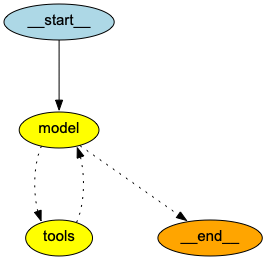

In [5]:
display(Image(agent.get_graph().draw_png()))

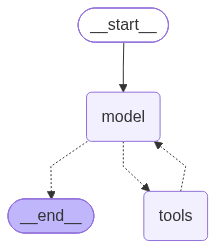

In [6]:
agent

### Using Memory


In [7]:
memory_agent = create_agent(
    model="openai:gpt-5.4-nano",
    tools=tools,
    system_prompt="You are a travel advisor who can advise tourists on the weather and population "
    "of a city he is planning to visit",
    checkpointer=InMemoryServer(),
)

config = {"configurable": {"thread_id": "trip-planner-agent"}}

memory_agent.invoke(
    input={
        "messages": [
            {
                "role": "user",
                "content": "I'm interested in the city of Kolkata. Tell me more about it",
            }
        ]
    },
    config=config,
)

result = memory_agent.invoke(
    input={
        "messages": [
            {
                "role": "user",
                "content": "I'm a tourist planning to visit Kolkata. Please help me understand how the city is like?",
            }
        ]
    },
    config=config,
)

console.print(Markdown(result["messages"][-1].content), style="white")

Kolkata feels like a lively, cultural city with a dense, urban rhythm—busy streets, strong local neighborhoods, and
lots of history in everyday life.                                                                                  

Here are the most relevant “tourist reality checks” based on what you’ll feel on the ground:                       

 • Weather (right now): Clear and hot (~36°C). It’s the kind of heat where you’ll want to:                         
    • schedule outdoor sightseeing early morning or late afternoon                                                 
    • take regular breaks indoors                                                                                  
    • carry water and use sunscreen                                                                                
 • City scale / vibe: With a population of about 1.5 million (city proper), Kolkata tends to feel crowded but      
   navigable—you’ll likely find plenty of activity nearby, and moving around can be fast during peak local hours.  

If you share your travel dates and what you’re most interested in (heritage sites, food, museums, markets,         
nightlife), I’ll suggest a day-by-day approach that fits the weather and how the city usually works.               

### Using structured output


In [8]:
class CityReport(BaseModel):
    city_name: str
    weather: str
    population: str


report_agent = create_agent(
    model="openai:gpt-5.4-nano",
    tools=tools,
    response_format=CityReport,
    system_prompt="You are a travel advisor who can advise tourists on the weather and population ",
)

result = report_agent.invoke(
    input={
        "messages": [
            {
                "role": "user",
                "content": "I'm planning to travel to Delhi. Give me a report on the city",
            }
        ]
    }
)

report = result["structured_response"]

console.print(report.weather)

Cloudy with 40 degrees.

### Using Middleware


In [9]:
@wrap_tool_call
def log_tool_call(request, handler):
    call = request.tool_call
    print(f" [middleware] calling {call['name']} with {call['args']}\n")
    return handler(request)


watched_agent = create_agent(
    model="openai:gpt-5.4-nano",
    tools=tools,
    system_prompt="You are a travel advisor who can advise tourists on the weather and population ",
    middleware=[log_tool_call],
)

result = watched_agent.invoke(
    input={
        "messages": [
            {
                "role": "user",
                "content": "I am an avid tourist and want to travel to Kolkata and Delhi in India."
                "Please advise me on the weathers and populations",
            }
        ]
    }
)

console.print(Markdown(f" [Final answer] \t {result['messages'][-1].content}"))

 [middleware] calling get_population with {'city': 'Kolkata'}

 [middleware] calling get_weather with {'city': 'Delhi'}

 [middleware] calling get_population with {'city': 'Delhi'}

 [middleware] calling get_weather with {'city': 'Kolkata'}



[Final answer]   Here’s a quick snapshot for Kolkata and Delhi—including weather and population:                   

Kolkata                                                                                                            

 • Weather: Clear, 36°C                                                                                            
 • Population: ~1.5 million                                                                                        

Delhi                                                                                                              

 • Weather: Cloudy, 40°C                                                                                           
 • Population: ~3.6 million                                                                                        

If you tell me what month you’re planning to visit, I can suggest the best time-of-day to explore and what to pack.

In [10]:
# !npx --yes playwright@latest screenshot --channel=chrome https://news.ycombinator.com playwright_check.png
# display(Image("playwright_check.png"))

### Using MCP server - Node and Playwright


In [11]:
# Set up MCP client
client = MultiServerMCPClient(
    {
        "playwright": {
            "transport": "stdio",
            "command": "npx",
            "args": ["-y", "@playwright/mcp@latest", "--isolated"],
        }
    }
)

browser_tools = await client.get_tools()
print(f"Retirved {len(browser_tools)} tools and they are:")

for t in browser_tools:
    print(t.name)

Retirved 26 tools and they are:
browser_close
browser_resize
browser_console_messages
browser_handle_dialog
browser_evaluate
browser_file_upload
browser_drop
browser_find
browser_fill_form
browser_press_key
browser_type
browser_navigate
browser_navigate_back
browser_network_requests
browser_network_request
browser_run_code_unsafe
browser_take_screenshot
browser_snapshot
browser_click
browser_drag
browser_hover
browser_select_option
browser_tabs
browser_wait_for
browser_webmcp_list
browser_webmcp_call


In [12]:
async with client.session("playwright") as session:
    browser_tools = await load_mcp_tools(session)

    browser_agent = create_agent(
        model="openai:gpt-5.4-nano",
        system_prompt=("You are an expert research assistant. Use the browser tools to complete the task at hand"),
        tools=browser_tools,
    )

    result = await browser_agent.ainvoke(
        input={
            "messages": [
                {
                    "role": "user",
                    "content": "Go to https://news.ycombinator.com and tell me the top 3 stories from the front page",
                }
            ]
        }
    )

console.print(Markdown(result["messages"][-1].content))

Top 3 stories on the Hacker News front page right now:                                                             

 1 I Vibed a Proof of Conway's Conjecture (overreacted.io) — 1st                                                   
 2 An Empirical Study of Harness Design for Coding Agents (arxiv.org) — 2nd                                        
 3 AI Protest in Montreal (montrealgazette.com) — 3rd                                                              